# Quá khớp, chưa khớp và đánh đổi thiên lệch – phương sai

Cùng dữ liệu $y = \sin(2\pi x) + \text{nhiễu}$ (15 điểm huấn luyện) như notebook 06.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression

def make_data(n, rng):
    """Sinh n điểm (x, y) với y = sin(2πx) + nhiễu, x trong [0, 1)."""
    x = np.sort(rng.uniform(0, 1, n))
    y = np.sin(2 * np.pi * x) + rng.normal(0, 0.2, n)
    return x.reshape(-1, 1), y

rng = np.random.default_rng(1)               # cố định bộ sinh số ngẫu nhiên
X_train, y_train = make_data(15, rng)        # tập huấn luyện: 15 điểm
X_val, y_val = make_data(15, rng)            # tập xác thực: 15 điểm
X_test, y_test = make_data(500, rng)         # tập kiểm tra: 500 điểm


def poly_model(degree):
    """Hồi quy đa thức bậc degree: chuẩn hóa x, tạo [x, x², …, x^degree], chuẩn hóa lại, rồi hồi quy tuyến tính."""
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                         StandardScaler(), LinearRegression())


def rmse(model, X, y):
    """Căn bậc hai của sai số bình phương trung bình."""
    return np.sqrt(np.mean((model.predict(X) - y) ** 2))

## 1. Ba mức độ phức tạp

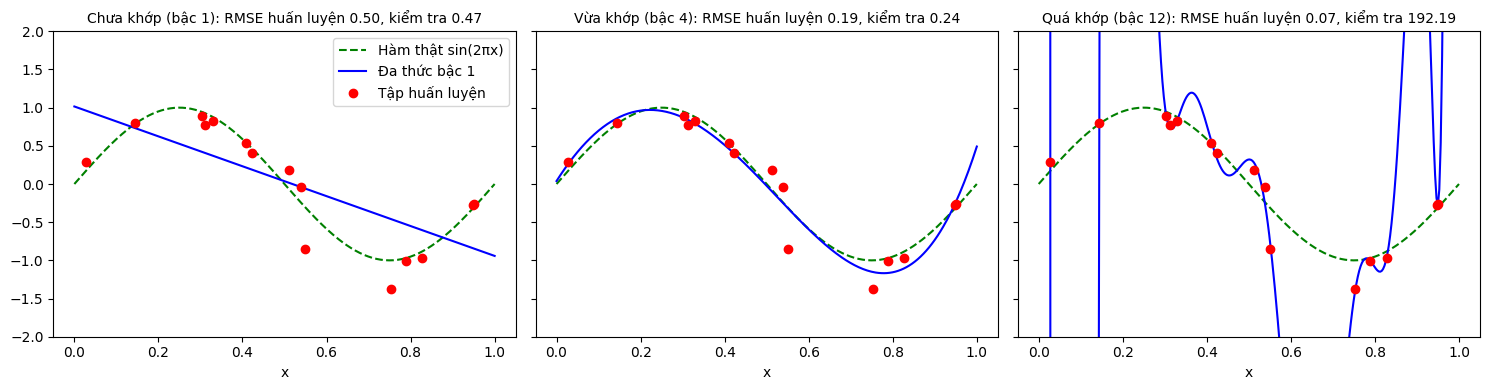

In [2]:
x_plot = np.linspace(0, 1, 300).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, degree, title in zip(axes, [1, 4, 12], ['Chưa khớp', 'Vừa khớp', 'Quá khớp']):
    model = poly_model(degree).fit(X_train, y_train)
    ax.plot(x_plot, np.sin(2 * np.pi * x_plot), 'g--', label='Hàm thật sin(2πx)')
    ax.plot(x_plot, model.predict(x_plot), 'b', label=f'Đa thức bậc {degree}')
    ax.plot(X_train, y_train, 'ro', label='Tập huấn luyện')
    ax.set_ylim(-2, 2)
    ax.set_title(f'{title} (bậc {degree}): RMSE huấn luyện {rmse(model, X_train, y_train):.2f}, '
                 f'kiểm tra {rmse(model, X_test, y_test):.2f}', fontsize=10)
    ax.set_xlabel('x')
axes[0].legend()
plt.tight_layout()
plt.show()

## 2. Đánh giá chất lượng qua tham số: độ lớn của trọng số

In [3]:
for degree in [1, 4, 12]:
    model = poly_model(degree).fit(X_train, y_train)
    largest = np.abs(model[-1].coef_).max()      # trọng số có độ lớn lớn nhất
    print(f'bậc {degree:2d}: RMSE huấn luyện = {rmse(model, X_train, y_train):.3f}, '
          f'RMSE kiểm tra = {rmse(model, X_test, y_test):8.3f}, |w| lớn nhất = {largest:.1e}')

bậc  1: RMSE huấn luyện = 0.495, RMSE kiểm tra =    0.474, |w| lớn nhất = 5.4e-01
bậc  4: RMSE huấn luyện = 0.187, RMSE kiểm tra =    0.240, |w| lớn nhất = 1.6e+00
bậc 12: RMSE huấn luyện = 0.074, RMSE kiểm tra =  192.193, |w| lớn nhất = 1.3e+04


Mô hình quá khớp có các trọng số **rất lớn** và trái dấu nhau để triệt tiêu: một thay đổi nhỏ của $x$ làm $\hat{y}$ thay đổi mạnh. Trọng số bất thường là dấu hiệu cảnh báo quá khớp ngay cả khi chưa có tập kiểm tra.

## 3. Sai số theo độ phức tạp của mô hình

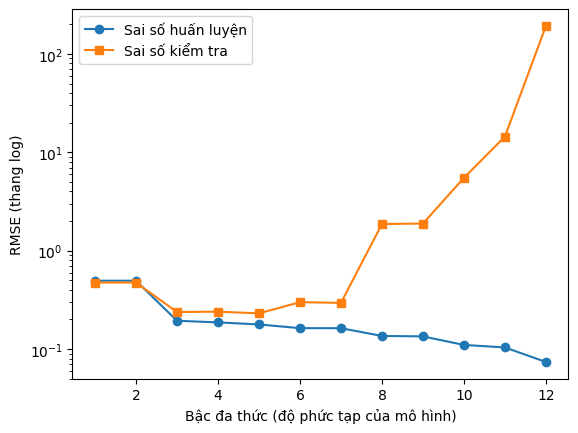

In [4]:
degrees = range(1, 13)
train_errors = [rmse(poly_model(d).fit(X_train, y_train), X_train, y_train) for d in degrees]
test_errors = [rmse(poly_model(d).fit(X_train, y_train), X_test, y_test) for d in degrees]
plt.plot(degrees, train_errors, 'o-', label='Sai số huấn luyện')
plt.plot(degrees, test_errors, 's-', label='Sai số kiểm tra')
plt.yscale('log')
plt.xlabel('Bậc đa thức (độ phức tạp của mô hình)')
plt.ylabel('RMSE (thang log)')
plt.legend()
plt.show()

## 4. Phân rã thiên lệch – phương sai bằng mô phỏng

Lặp lại 200 lần: sinh một tập huấn luyện 15 điểm mới, huấn luyện mô hình, ghi lại dự đoán trên một lưới điểm $x$. Khi đó $\text{Bias}^2 = (\mathbb{E}[\hat{f}(x)] - f(x))^2$ và $\text{Variance} = \mathbb{E}[(\hat{f}(x) - \mathbb{E}[\hat{f}(x)])^2]$, lấy trung bình trên lưới.

In [5]:
x_grid = np.linspace(0.05, 0.95, 50).reshape(-1, 1)
f_true = np.sin(2 * np.pi * x_grid.ravel())             # hàm thật f(x)
print('bậc   Bias²   Variance   Tổng (+ σ² = 0.04)')
for degree in range(1, 8):
    sim_rng = np.random.default_rng(7)                 # mọi bậc dùng cùng 200 tập huấn luyện
    predictions = []
    for _ in range(200):
        X_sim, y_sim = make_data(15, sim_rng)          # một tập huấn luyện mới
        predictions.append(poly_model(degree).fit(X_sim, y_sim).predict(x_grid))
    predictions = np.array(predictions)                # 200 x 50
    mean_prediction = predictions.mean(axis=0)          # E[f̂(x)]
    bias2 = np.mean((mean_prediction - f_true) ** 2)
    variance = np.mean(predictions.var(axis=0))
    print(f'{degree:3d}  {bias2:7.4f}  {variance:8.4f}  {bias2 + variance + 0.04:8.4f}')

bậc   Bias²   Variance   Tổng (+ σ² = 0.04)


  1   0.1539    0.0401    0.2340


  2   0.1444    0.1138    0.2982


  3   0.0026    0.0161    0.0586


  4   0.0043    0.0884    0.1326


  5   0.0015    0.2132    0.2547


  6   0.0280    4.6476    4.7156


  7   0.1311   27.9201   28.0912


Bậc 1, 2 có **thiên lệch cao** (quá đơn giản để biểu diễn hình sin). Từ bậc 4 trở lên, thiên lệch nhỏ nhưng **phương sai tăng nhanh** (mô hình thay đổi mạnh theo từng tập huấn luyện). Tổng sai số nhỏ nhất ở bậc 3: đó là độ phức tạp tối ưu. Với bậc cao hơn nữa, một vài tập huấn luyện làm mô hình "bùng nổ" ở hai đầu đoạn và phương sai lên tới hàng nghìn.

## 5. Khắc phục quá khớp

In [6]:
from sklearn.linear_model import Ridge

more_rng = np.random.default_rng(3)
X_big, y_big = make_data(200, more_rng)                 # thêm dữ liệu: 200 điểm huấn luyện
ridge_model = make_pipeline(StandardScaler(), PolynomialFeatures(12, include_bias=False),
                            StandardScaler(), Ridge(alpha=0.1))   # điều chuẩn L2
cases = [('Bậc 12, 15 điểm', poly_model(12).fit(X_train, y_train)),
         ('Bậc 12, 200 điểm', poly_model(12).fit(X_big, y_big)),
         ('Bậc 12 + Ridge, 15 điểm', ridge_model.fit(X_train, y_train)),
         ('Bậc 4, 15 điểm', poly_model(4).fit(X_train, y_train))]
for name, model in cases:
    print(f'{name:24s} RMSE kiểm tra = {rmse(model, X_test, y_test):.3f}')

Bậc 12, 15 điểm          RMSE kiểm tra = 192.193
Bậc 12, 200 điểm         RMSE kiểm tra = 0.222
Bậc 12 + Ridge, 15 điểm  RMSE kiểm tra = 0.243
Bậc 4, 15 điểm           RMSE kiểm tra = 0.240
